### Characterizing the window features before looking for respiration states

Every 2 s window of every Aim1 recording, built by `full_recording_feature_extraction.py`
into `../data/whole-session-final/`. Valence and rank are analysed separately below —
same four checks on each.

**Dropped recordings — 8 of 35.** `DROP` in the extraction script is the source of truth;
see also [`../docs/EXCLUSIONS_LOG.md`](../docs/EXCLUSIONS_LOG.md). Do **not** add or remove
an exclusion without asking first.

| Recording | Why |
|---|---|
| `BLRI_s5_13_…175809` | no `resp` dataset in the H5 at all, only `ekg` |
| `RI1_s5_13_…181801` | whole-session resp rate outlier (~4.9 Hz vs ~7.5) |
| `RI2_s5_13_…184136` | resp trace flat/broken (std ≈ 20 vs ~700–1000) |
| `CM_s3_5_d3_6_…170708` | duplicate 3_5 cagemate session |
| `RI1_s3_5_…105014` | no BORIS export |
| `CM_s3_6_sub3_5_…174348` | BORIS export is empty |
| `RI2_s3_5_…112618` | incomplete session (213 s vs ~605 s), unpaired once `RI1_3_5` went |
| `CM_s3_5_d3_6_…160001` | short (355 s) and, with 3_6 gone, the lone occupant of cage 3 |

Subject **3_5 is now out entirely** (no valence and no rank recording), so valence is
**7 mice** and rank is **6 mice / 3 complete cages** — every leave-one-cage-out fold now has
both ranks in it. Kept filenames that mention `3_5`/`3_6` refer to them as the **cagemate**,
not the focal animal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Resolves whether the kernel starts in respiration-states/, resp_classification/, or repo root.
DATA_SUB = Path("data") / "whole-session-final"
DATA_DIR = next(c / DATA_SUB for c in (Path(".."), Path("."),
                Path("notebooks/thomas_notebooks/resp_classification"))
                if (c / DATA_SUB / "full-recording-manifest.csv").exists())
_pq = DATA_DIR / "full-recording-features-2sec.parquet"
df = pd.read_parquet(_pq) if _pq.exists() else pd.read_pickle(_pq.with_suffix(".pkl"))
manifest = pd.read_csv(DATA_DIR / "full-recording-manifest.csv")

META = ["WindowID", "Start", "Stop", "Duration", "WindowIndex",
        "RecordingID", "Dataset", "Condition", "Subject", "Cagemate", "Cage", "Rank"]
num = df.select_dtypes("number").columns.difference(META)
# Pause CVs are undefined unless a window has >=2 pauses of that type -> mostly NaN.
FEATURES = sorted(c for c in num if df[c].isna().mean() < 0.5)

valence = df[df.Dataset == "valence"]
rank = df[df.Dataset == "rank"]

print(f"{len(df)} windows from {df.RecordingID.nunique()} recordings, "
      f"{df.Subject.nunique()} mice, {len(FEATURES)} features")
print(df.groupby(["Dataset", "Condition"]).size().to_string())

7780 windows from 27 recordings, 7 mice, 25 features
Dataset  Condition          
rank     CagemateInteraction    1743
valence  Baseline               2092
         Negative               1870
         Positive               2075


In [2]:
df.head()

,WindowID,Start,Stop,Duration,n_breaths,breathing_rate_hz,mean_ibi_sec,cv_ibi,mean_inhale_dur_sec,cv_inhale_dur,...,inhale_duty_cycle,exhale_duty_cycle,WindowIndex,RecordingID,Dataset,Condition,Subject,Cagemate,Cage,Rank
0,0,0.0,2.0,2.0,9,4.539007,0.220312,0.627058,0.139444,0.872460,...,0.632939,0.303861,0,CM_s1_1_d1_2_20250623_111352_merged,rank,CagemateInteraction,1_1,1_2,1,Subordinate
1,1,2.0,4.0,2.0,18,9.176788,0.108971,0.139674,0.053611,0.131181,...,0.491978,0.472859,1,CM_s1_1_d1_2_20250623_111352_merged,rank,CagemateInteraction,1_1,1_2,1,Subordinate
2,2,4.0,6.0,2.0,17,8.488064,0.117813,0.292488,0.046471,0.160926,...,0.394445,0.549228,2,CM_s1_1_d1_2_20250623_111352_merged,rank,CagemateInteraction,1_1,1_2,1,Subordinate
3,3,6.0,8.0,2.0,20,9.718670,0.102895,0.210676,0.044750,0.285900,...,0.434910,0.515090,3,CM_s1_1_d1_2_20250623_111352_merged,rank,CagemateInteraction,1_1,1_2,1,Subordinate
4,4,8.0,10.0,2.0,20,10.482759,0.095395,0.064901,0.042625,0.138142,...,0.446828,0.501862,4,CM_s1_1_d1_2_20250623_111352_merged,rank,CagemateInteraction,1_1,1_2,1,Subordinate


#### With < 10% of the data having < 8 Breaths per 2 second timestep, extraction should be reliable

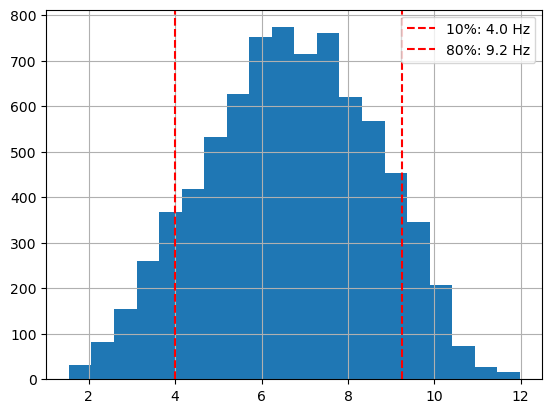

In [3]:
ax = df["breathing_rate_hz"].hist(bins=20)

p10 = df["breathing_rate_hz"].quantile(.10)
p80 = df["breathing_rate_hz"].quantile(.90)

ax.axvline(
    p10,
    color="red",
    ls="--",
    label=f"10%: {p10:.1f} Hz"
)
ax.axvline(
    p80,
    color="red",
    ls="--",
    label=f"80%: {p80:.1f} Hz"
)
ax.legend()

In [4]:
nans = df.isna().mean() * 100 > 0
nans

WindowID                         False
Start                            False
Stop                             False
Duration                         False
n_breaths                        False
breathing_rate_hz                False
mean_ibi_sec                     False
cv_ibi                           False
mean_inhale_dur_sec              False
cv_inhale_dur                    False
mean_exhale_dur_sec              False
cv_exhale_dur                    False
ie_ratio                         False
mean_peak_insp_flow              False
mean_peak_exp_flow               False
cv_peak_insp_flow                False
mean_inhale_vol                  False
mean_exhale_vol                  False
mean_tidal_vol_proxy             False
cv_inhale_vol                    False
ventilation_proxy                False
pct_breaths_with_inhale_pause    False
mean_inhale_pause_dur_sec        False
cv_inhale_pause_dur               True
inhale_pause_duty_cycle          False
pct_breaths_with_exhale_p

### Paired recordings (both datasets)

In [5]:
# Recordings that should be paired, and whether they are comparable in length.
# Three families: the same mouse across valence conditions; the two focal directions of
# one cage; and cross-dataset (the same mice appear in valence AND rank). Written to
# data/full-recording-pairs.json. Mice whose partner recording was dropped are unpaired
# by design -- see the missing-recordings print at the bottom.
TOL = 0.05                      # sessions are nominally ~10 min
VAL = ["Baseline", "Positive", "Negative"]
dur = dict(zip(manifest.RecordingID, manifest.session_duration_sec))
by = {(r.Subject, r.Condition): r.RecordingID for r in manifest.itertuples()}

def _pair(kind, key, a, b):
    lo, hi = sorted((dur[a], dur[b]))
    return dict(kind=kind, key=key, a=a, b=b, dur_a=round(dur[a], 1),
                dur_b=round(dur[b], 1), ratio=round(lo / hi, 2),
                equal_length=bool(hi - lo <= TOL * hi))

rows, subs = [], sorted(manifest.Subject.unique())
for s in subs:
    have = [c for c in VAL if (s, c) in by]
    rows += [_pair("valence_within_subject", f"{s}:{a}-{b}", by[(s, a)], by[(s, b)])
             for i, a in enumerate(have) for b in have[i + 1:]]
    if (s, "CagemateInteraction") in by:
        rows += [_pair("cross_dataset_mouse", f"{s}:CM-{c}",
                       by[(s, "CagemateInteraction")], by[(s, c)]) for c in have]
for cage, g in manifest[manifest.Dataset == "rank"].groupby("Cage"):
    ids = sorted(g.RecordingID)
    rows += [_pair("rank_reciprocal", f"cage{cage}", a, b)
             for i, a in enumerate(ids) for b in ids[i + 1:]]

pair_df = pd.DataFrame(rows)
(DATA_DIR / "full-recording-pairs.json").write_text(
    pair_df.to_json(orient="records", indent=1))
print(f"{len(pair_df)} pairs, {(~pair_df.equal_length).sum()} unequal (>{TOL:.0%})")
print(pair_df.kind.value_counts().to_string())
display(pair_df[~pair_df.equal_length])

want = VAL + ["CagemateInteraction"]
print("missing recordings per mouse (never recorded, or dropped):",
      {s: [c for c in want if (s, c) not in by]
       for s in subs if any((s, c) not in by for c in want)})

42 pairs, 0 unequal (>5%)
kind
valence_within_subject    21
cross_dataset_mouse       18
rank_reciprocal            3


,kind,key,a,b,dur_a,dur_b,ratio,equal_length


missing recordings per mouse (never recorded, or dropped): {'3_6': ['CagemateInteraction']}


### The four checks, defined once and run on each dataset below

Lengths & yield · are the features Gaussian · which features are redundant · is PCA compressible and readable.

In [6]:
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from scipy.stats import kurtosis, shapiro, skew
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


def lengths(d, name):
    """Session duration and window yield for the recordings in this dataset."""
    q = manifest[manifest.RecordingID.isin(d.RecordingID.unique())]
    display(q.sort_values("session_duration_sec")[
        ["RecordingID", "Condition", "Subject", "session_duration_sec",
         "n_windows_possible", "n_windows_kept", "window_yield"]])
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    sns.stripplot(data=q, x="Condition", y="session_duration_sec", s=8, ax=ax[0])
    ax[0].set_title(f"{name}: session duration")
    ax[1].scatter(q.n_windows_possible, q.n_windows_kept)
    ax[1].axline((0, 0), slope=1, ls="--", c="grey")
    ax[1].set(xlabel="windows possible", ylabel="windows kept",
              title=f"{name}: window yield")
    plt.tight_layout()


def gaussian(d, name, nmax=5000):
    """Is each feature Gaussian, and where does its mass actually sit?

    Shapiro-Wilk W (1.0 = normal) on a 5k subsample, since p is ~0 at this n for
    anything. pct_zero and the 1st/99th percentiles are here because several features
    are mostly zero -- a histogram alone just looks like one bar.
    """
    rng = np.random.default_rng(0)
    t = pd.DataFrame([
        dict(feature=f, skewness=skew(x), excess_kurt=kurtosis(x),
             shapiro_W=shapiro(rng.choice(x, min(len(x), nmax), replace=False)).statistic,
             pct_zero=100 * (x == 0).mean(), p1=np.percentile(x, 1),
             median=np.median(x), p99=np.percentile(x, 99), max=x.max())
        for f, x in ((f, d[f].dropna().to_numpy()) for f in FEATURES)
    ]).set_index("feature").sort_values("skewness", key=abs, ascending=False)
    print(f"{name}: |skew| >= 2 in {(t.skewness.abs() >= 2).sum()}/{len(t)}, "
          f"excess kurtosis >= 7 in {(t.excess_kurt >= 7).sum()}, "
          f"Shapiro W < 0.95 in {(t.shapiro_W < 0.95).sum()} -> not Gaussian")
    display(t.round(3))

    ncol = 5
    nrow = int(np.ceil(len(FEATURES) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3 * ncol, 2.2 * nrow))
    for ax, f in zip(axes.ravel(), t.index):
        x = d[f].dropna()
        lo, hi = x.quantile([0.01, 0.99])   # clip: heavy tails otherwise squash the bulk
        ax.hist(x, bins=50, range=(lo, hi) if hi > lo else None)
        ax.set_title(f"{f}\nskew={t.skewness[f]:.1f}  W={t.shapiro_W[f]:.2f}  "
                     f"{t.pct_zero[f]:.0f}% zero", fontsize=7)
        ax.set_yticks([])
    for ax in axes.ravel()[len(FEATURES):]:
        ax.axis("off")
    fig.suptitle(f"{name}: distributions, 1st-99th percentile", y=1.002)
    plt.tight_layout()
    return t

def redundancy(d, name, thresh=0.85):
    """Near-duplicate features: which pairs, and which to drop.

    A 25x25 heatmap is unreadable, so only the features actually involved in a
    |rho| > thresh pair are plotted. The drop list still clusters on all features.
    """
    corr = d[FEATURES].corr(method="spearman")
    p = corr.abs().where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
    p = p[p > thresh].sort_values(ascending=False)
    hot = sorted({f for pair in p.index for f in pair})
    print(f"{name}: {len(p)} pairs with |rho| > {thresh}, involving {len(hot)} features")
    display(p.round(2))

    if hot:
        plt.figure(figsize=(1.5 + 0.55 * len(hot), 1 + 0.5 * len(hot)))
        sns.heatmap(corr.loc[hot, hot], cmap="RdBu_r", vmin=-1, vmax=1, center=0,
                    annot=True, fmt=".2f", annot_kws={"size": 7}, square=True)
        plt.title(f"{name}: only features in a |rho| > {thresh} pair")
        plt.tight_layout()
        plt.show()

    # One representative per redundant cluster: the member least correlated with
    # everything else, i.e. the one carrying the most independent information.
    Z = linkage(squareform((1 - corr.abs()).values, checks=False), "average")
    lab = fcluster(Z, 1 - thresh, "distance")
    mean_abs = corr.abs().mean()
    keep = {min(np.array(FEATURES)[lab == c], key=mean_abs.get) for c in np.unique(lab)}
    drop = sorted(set(FEATURES) - keep)
    print(f"{name}: drop {len(drop)} of {len(FEATURES)} -> {drop}")
    return sorted(keep), drop

def pca_check(d, name, cols=None, hue="Condition"):
    """How many PCs carry the variance, and are the loadings readable?"""
    cols = cols or FEATURES
    X = np.log1p(d[cols].clip(lower=0))   # most features are heavily right-skewed
    X = StandardScaler().fit_transform(X.fillna(X.median()))
    pca = PCA().fit(X)
    cum = pca.explained_variance_ratio_.cumsum()
    print(f"{name}: PCs for 80/90/95% = "
          f"{[int(np.searchsorted(cum, t) + 1) for t in (0.8, 0.9, 0.95)]}")

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(np.arange(1, len(cum) + 1), cum, "o-")
    ax[0].set(xlabel="n PCs", ylabel="cumulative variance", ylim=(0, 1), title=name)
    scores = pca.transform(X)
    for lvl, idx in d.reset_index(drop=True).groupby(hue).indices.items():
        ax[1].scatter(scores[idx, 0], scores[idx, 1], s=3, alpha=0.3, label=lvl)
    ax[1].legend(markerscale=4)
    ax[1].set(xlabel="PC1", ylabel="PC2", title=f"{name}: windows by {hue}")
    plt.tight_layout()

    loadings = pd.DataFrame(pca.components_[:5].T, index=cols,
                            columns=[f"PC{i+1}" for i in range(5)])
    plt.figure(figsize=(6, 8))
    sns.heatmap(loadings, cmap="RdBu_r", center=0)
    plt.title(f"{name}: loadings")
    return pca, scores, cols


def save_pcs(pca, scores, cols, d, name, var=0.95):
    """Is each top PC one feature, or a blend? Save the PCs covering `var` variance.

    "clean" = the top loading is >1.5x the next, i.e. the PC is essentially that one
    feature rescaled. Saved scores are the input for later k-means / HMM state work.
    """
    k = int(np.searchsorted(pca.explained_variance_ratio_.cumsum(), var) + 1)
    load = pd.DataFrame(pca.components_[:k].T, index=cols)
    for i in range(min(k, 6)):
        top = load[i].abs().nlargest(3)
        verdict = "clean" if top.iloc[0] > 1.5 * top.iloc[1] else "mixed"
        print(f"  PC{i+1} {pca.explained_variance_ratio_[i]:5.1%} {verdict:5s} "
              + ", ".join(f"{f}({load[i][f]:+.2f})" for f in top.index))
    out = d[["RecordingID", "Condition", "Subject", "Cage", "Rank",
             "WindowIndex"]].reset_index(drop=True)
    out[[f"PC{i+1}" for i in range(k)]] = scores[:, :k]
    out.to_pickle(DATA_DIR / f"full-recording-pcs-{name}.pkl")
    print(f"  saved {k} PCs ({var:.0%} of variance) -> full-recording-pcs-{name}.pkl")
    return out

## Valence — BLRI (baseline), RI1 (positive), RI2 (negative)

,RecordingID,Condition,Subject,session_duration_sec,n_windows_possible,n_windows_kept,window_yield
9,RI1_s2_3_p5_3_nRB3_20250622_104059_merged,Positive,2_3,602.95,301,279,0.927
20,RI2_s4_8_p5_1_nRB3_20250621_171318_merged,Negative,4_8,603.24,301,297,0.987
11,RI1_s3_6_p5_3_nRB3_20250621_125312_merged,Positive,3_6,603.27,301,296,0.983
3,BLRI_s2_4_p5_4_nRB3_20250622_121708_merged,Baseline,2_4,603.95,301,292,0.970
5,BLRI_s4_7_p5_2_nRB3_20250621_144806_merged,Baseline,4_7,604.09,302,294,0.974
15,RI2_s1_2_p5_1_nRB6_20250622_173049_merged,Negative,1_2,604.26,302,266,0.881
8,RI1_s1_2_p5_1_nRB6_20250622_170742_merged,Positive,1_2,604.48,302,288,0.954
14,RI2_s1_1_p5_2_nRB6_20250622_150457_merged,Negative,1_1,604.79,302,297,0.983
13,RI1_s4_8_p5_1_nRB3_20250621_165214_merged,Positive,4_8,604.84,302,294,0.974
6,BLRI_s4_8_p5_1_nRB3_20250621_163506_merged,Baseline,4_8,605.01,302,300,0.993


Valence: |skew| >= 2 in 14/25, excess kurtosis >= 7 in 17, Shapiro W < 0.95 in 22 -> not Gaussian


,skewness,excess_kurt,shapiro_W,pct_zero,p1,median,p99,max
feature,,,,,,,,
mean_inhale_pause_dur_sec,75.404,5790.553,0.009,90.939,0.000,0.000,0.192,4.954500e+01
inhale_pause_duty_cycle,73.153,5540.537,0.058,90.939,0.000,0.000,0.129,3.162700e+01
mean_exhale_pause_dur_sec,45.932,2737.239,0.268,57.661,0.000,0.000,0.792,2.860000e+01
exhale_pause_duty_cycle,40.319,2198.823,0.232,57.661,0.000,0.000,0.592,2.163900e+01
mean_inhale_vol,37.930,2215.777,0.293,0.000,29197.227,53053.941,124396.838,2.083215e+06
inhale_duty_cycle,28.286,988.720,0.190,0.000,0.240,0.442,0.756,1.218500e+01
ie_ratio,22.261,705.832,0.318,0.000,0.462,0.882,2.490,2.852200e+01
ventilation_proxy,22.147,1115.577,0.567,0.000,238877.809,674305.416,1286175.675,1.600967e+07
mean_tidal_vol_proxy,21.483,983.772,0.488,0.000,59376.277,100668.162,200549.217,2.107940e+06


Valence: 9 pairs with |rho| > 0.85, involving 9 features


breathing_rate_hz          mean_ibi_sec                     1.00
inhale_pause_duty_cycle    mean_inhale_pause_dur_sec        1.00
                           pct_breaths_with_inhale_pause    1.00
mean_inhale_pause_dur_sec  pct_breaths_with_inhale_pause    1.00
exhale_pause_duty_cycle    mean_exhale_pause_dur_sec        0.99
                           pct_breaths_with_exhale_pause    0.96
breathing_rate_hz          n_breaths                        0.94
mean_ibi_sec               n_breaths                        0.94
mean_exhale_pause_dur_sec  pct_breaths_with_exhale_pause    0.93
dtype: float64

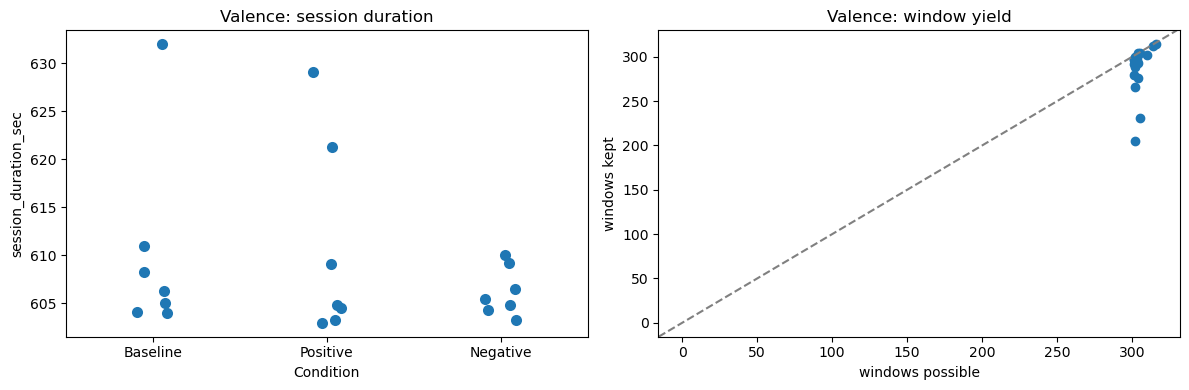

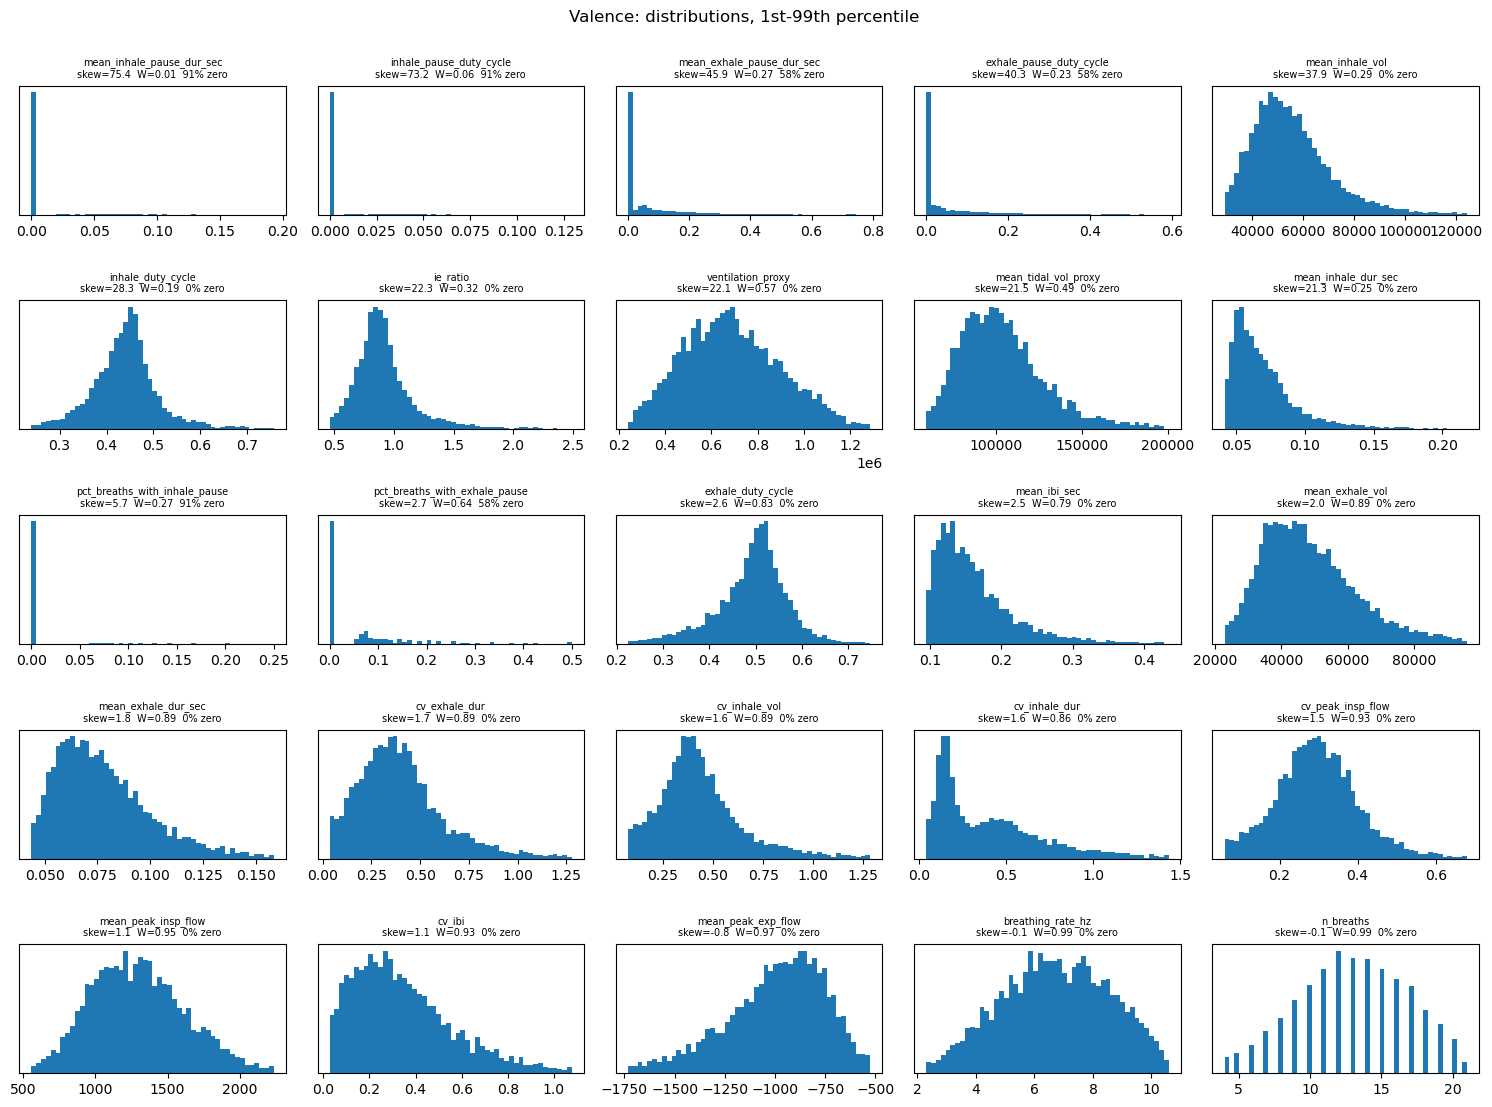

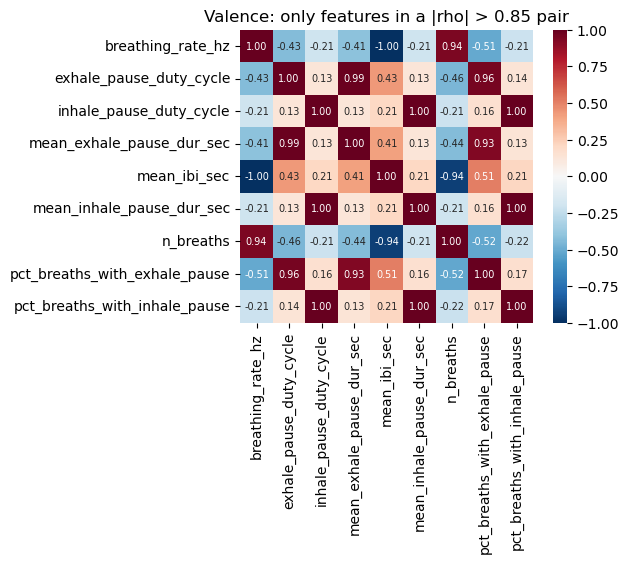

Valence: drop 6 of 25 -> ['breathing_rate_hz', 'exhale_pause_duty_cycle', 'inhale_pause_duty_cycle', 'mean_ibi_sec', 'pct_breaths_with_exhale_pause', 'pct_breaths_with_inhale_pause']
Valence: PCs for 80/90/95% = [6, 8, 9]
  PC1 23.9% mixed cv_inhale_dur(+0.38), ie_ratio(+0.36), mean_inhale_dur_sec(+0.35)
  PC2 19.1% mixed mean_inhale_vol(+0.48), mean_tidal_vol_proxy(+0.48), ventilation_proxy(+0.40)
  PC3 15.4% mixed mean_exhale_dur_sec(+0.54), n_breaths(-0.43), mean_exhale_vol(+0.37)
  PC4 14.0% mixed cv_exhale_dur(+0.47), cv_peak_insp_flow(+0.40), cv_ibi(+0.35)
  PC5  7.5% mixed exhale_duty_cycle(+0.55), mean_exhale_pause_dur_sec(-0.37), inhale_duty_cycle(+0.32)
  PC6  5.4% clean mean_inhale_pause_dur_sec(+0.94), mean_exhale_pause_dur_sec(-0.27), cv_peak_insp_flow(+0.11)
  saved 9 PCs (95% of variance) -> full-recording-pcs-valence.pkl


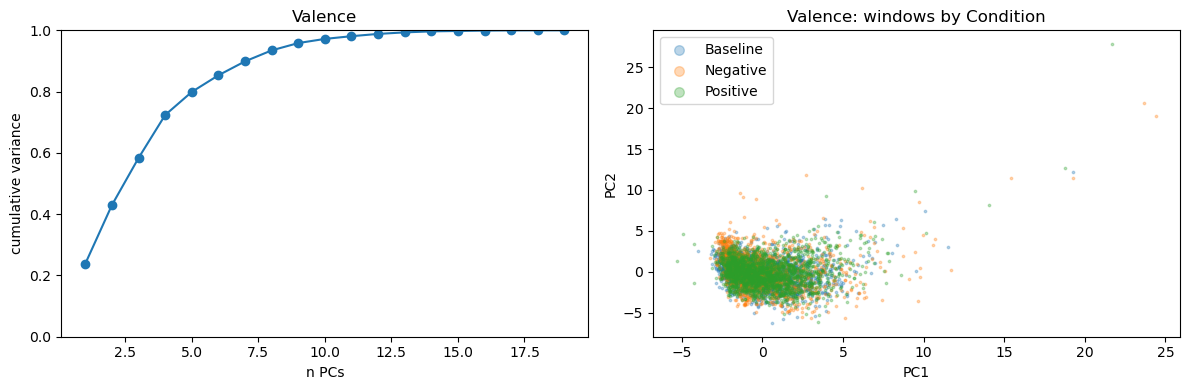

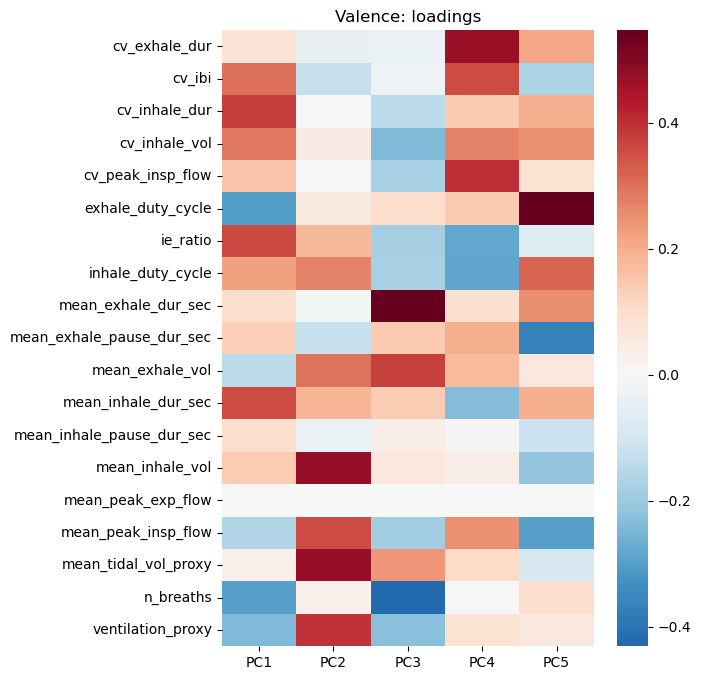

In [7]:
lengths(valence, "Valence")
gaussian(valence, "Valence")
VAL_KEEP, VAL_DROP = redundancy(valence, "Valence")
# PCA on the de-correlated set: with the redundant twins in, rate would be counted
# three times over and would dominate the PCs that later feed k-means / HMM.
VAL_PCA, VAL_SCORES, VAL_COLS = pca_check(valence, "Valence", cols=VAL_KEEP)
VAL_PCS = save_pcs(VAL_PCA, VAL_SCORES, VAL_COLS, valence, "valence")

## Rank — baseline cagemate interactions

,RecordingID,Condition,Subject,session_duration_sec,n_windows_possible,n_windows_kept,window_yield
25,CM_s4_7_d4_8_20250623_193718_merged,CagemateInteraction,4_7,603.19,301,301,1.000
26,CM_s4_8_sub4_7_20250623_182649_merged,CagemateInteraction,4_8,605.08,302,301,0.997
22,CM_s1_2_sub1_1_20250623_133932_merged,CagemateInteraction,1_2,605.66,302,265,0.877
23,CM_s2_3_d2_4_20250623_151153_merged,CagemateInteraction,2_3,611.43,305,298,0.977
21,CM_s1_1_d1_2_20250623_111352_merged,CagemateInteraction,1_1,612.62,306,269,0.879
24,CM_s2_4_sub2_3_20250623_143348_merged,CagemateInteraction,2_4,621.96,310,309,0.997


Rank: |skew| >= 2 in 12/25, excess kurtosis >= 7 in 10, Shapiro W < 0.95 in 18 -> not Gaussian


,skewness,excess_kurt,shapiro_W,pct_zero,p1,median,p99,max
feature,,,,,,,,
ie_ratio,31.270,1059.947,0.078,0.000,0.464,0.890,1.979,55.656
inhale_duty_cycle,26.687,758.048,0.120,0.000,0.229,0.439,0.656,10.250
mean_inhale_dur_sec,23.105,626.321,0.204,0.000,0.041,0.065,0.206,2.588
pct_breaths_with_inhale_pause,9.404,132.739,0.214,92.886,0.000,0.000,0.143,0.833
inhale_pause_duty_cycle,8.287,107.023,0.216,92.886,0.000,0.000,0.105,0.407
mean_inhale_pause_dur_sec,7.546,79.123,0.221,92.886,0.000,0.000,0.179,0.572
mean_exhale_pause_dur_sec,3.873,22.186,0.573,50.947,0.000,0.000,0.758,1.715
exhale_pause_duty_cycle,2.947,11.164,0.614,50.947,0.000,0.000,0.573,0.974
mean_inhale_vol,2.466,12.536,0.837,0.000,28305.525,52796.252,121201.926,206041.014


Rank: 14 pairs with |rho| > 0.85, involving 11 features


breathing_rate_hz          mean_ibi_sec                     1.00
inhale_pause_duty_cycle    mean_inhale_pause_dur_sec        1.00
                           pct_breaths_with_inhale_pause    1.00
mean_inhale_pause_dur_sec  pct_breaths_with_inhale_pause    1.00
exhale_pause_duty_cycle    mean_exhale_pause_dur_sec        0.98
breathing_rate_hz          n_breaths                        0.95
mean_ibi_sec               n_breaths                        0.95
exhale_pause_duty_cycle    pct_breaths_with_exhale_pause    0.94
mean_exhale_pause_dur_sec  pct_breaths_with_exhale_pause    0.89
mean_exhale_dur_sec        mean_ibi_sec                     0.87
breathing_rate_hz          mean_exhale_dur_sec              0.87
mean_ibi_sec               mean_inhale_dur_sec              0.86
breathing_rate_hz          mean_inhale_dur_sec              0.86
mean_inhale_dur_sec        n_breaths                        0.85
dtype: float64

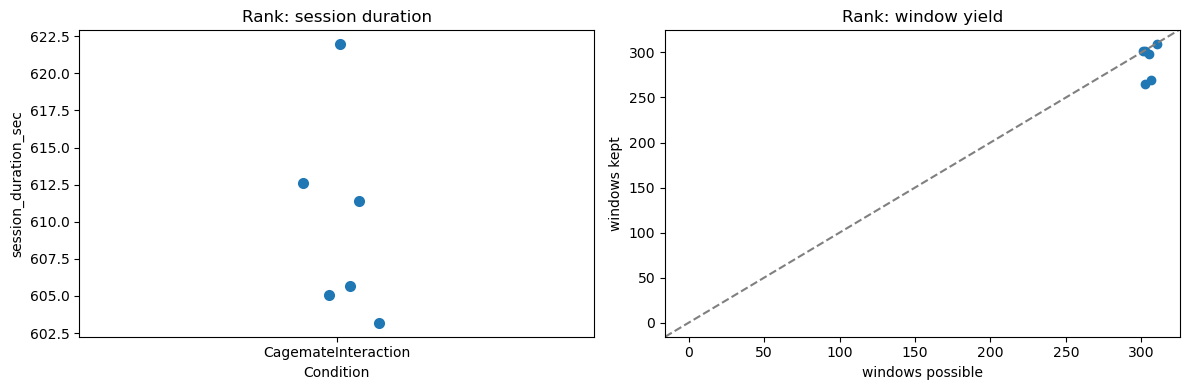

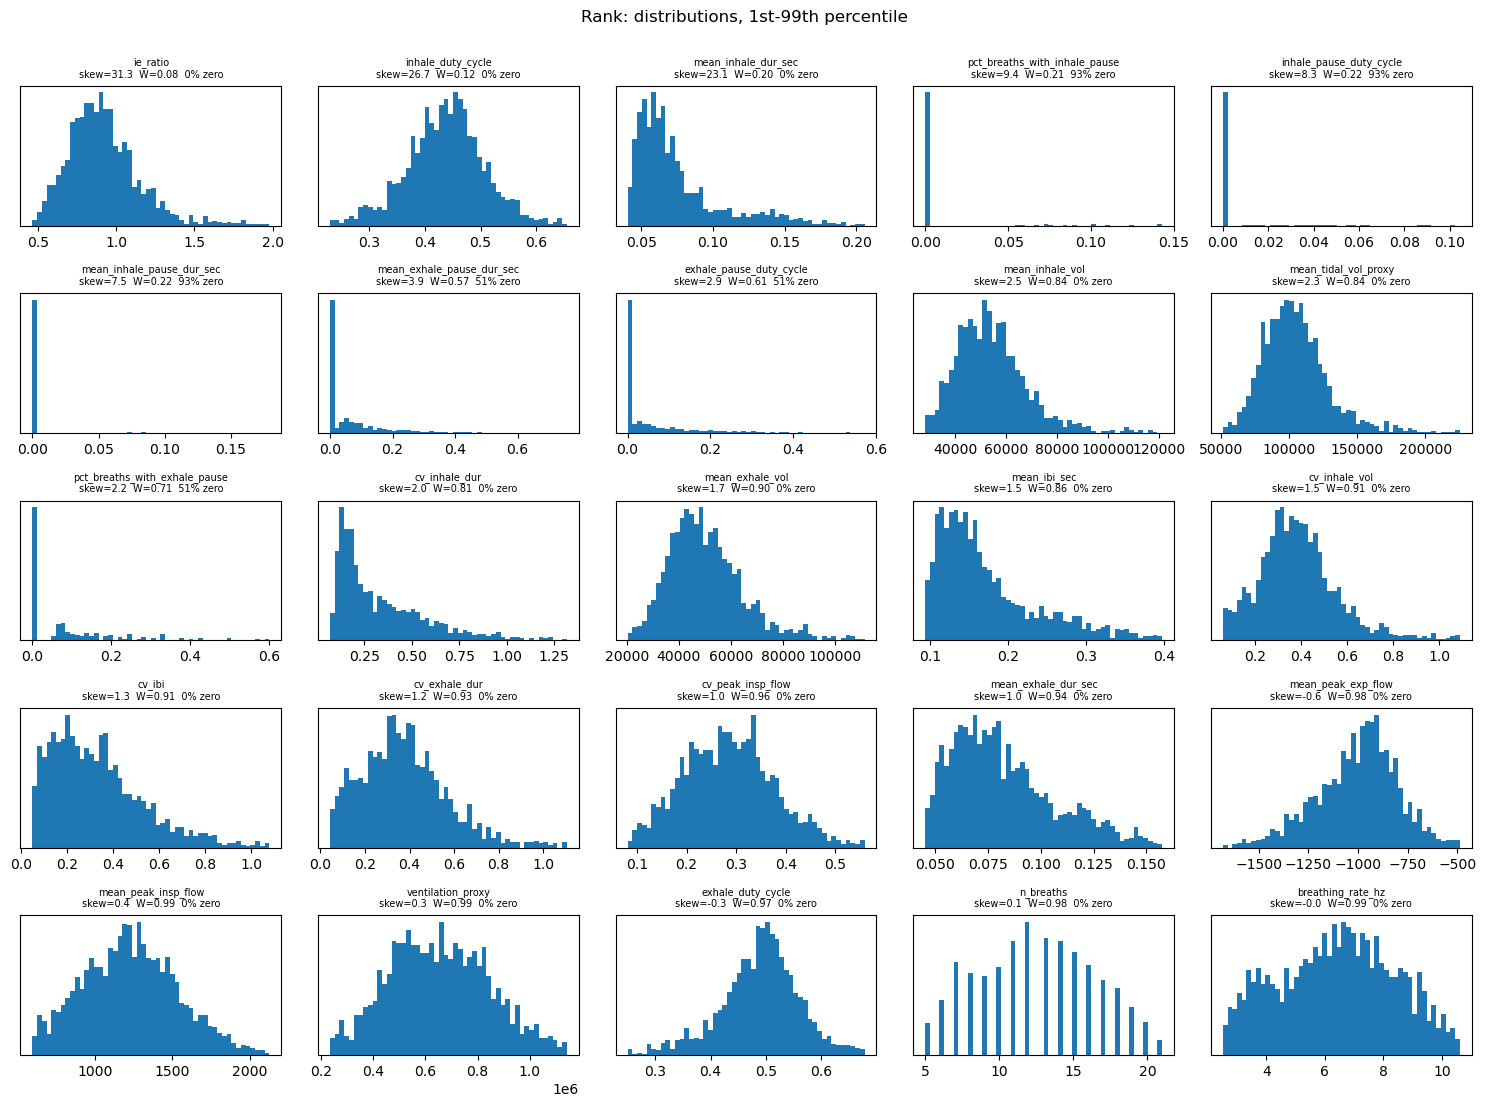

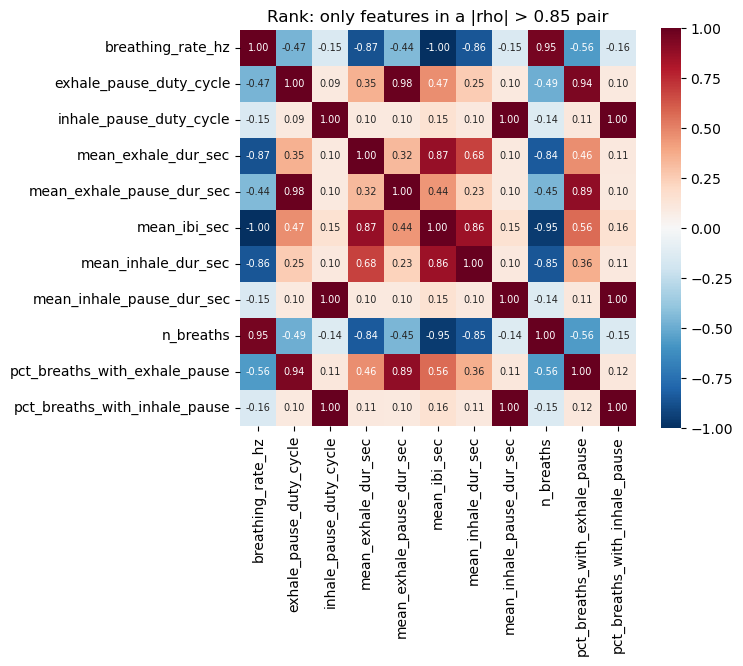

Rank: drop 7 of 25 -> ['breathing_rate_hz', 'exhale_pause_duty_cycle', 'mean_ibi_sec', 'mean_inhale_pause_dur_sec', 'n_breaths', 'pct_breaths_with_exhale_pause', 'pct_breaths_with_inhale_pause']
Rank: PCs for 80/90/95% = [5, 7, 9]
  PC1 21.9% mixed mean_tidal_vol_proxy(+0.41), mean_inhale_vol(+0.37), mean_exhale_vol(+0.34)
  PC2 21.2% mixed ie_ratio(+0.40), mean_inhale_dur_sec(+0.39), exhale_duty_cycle(-0.38)
  PC3 16.0% mixed mean_peak_insp_flow(+0.47), ventilation_proxy(+0.41), cv_inhale_vol(+0.36)
  PC4 14.2% mixed mean_exhale_dur_sec(+0.46), mean_exhale_vol(+0.42), inhale_duty_cycle(-0.34)
  PC5  6.9% mixed exhale_duty_cycle(+0.51), mean_exhale_pause_dur_sec(-0.41), mean_peak_insp_flow(-0.34)
  PC6  5.7% clean inhale_pause_duty_cycle(+0.96), mean_exhale_pause_dur_sec(-0.26), exhale_duty_cycle(+0.05)


  saved 9 PCs (95% of variance) -> full-recording-pcs-rank.pkl

drop in both: ['breathing_rate_hz', 'exhale_pause_duty_cycle', 'mean_ibi_sec', 'pct_breaths_with_exhale_pause', 'pct_breaths_with_inhale_pause']
drop in only one: ['inhale_pause_duty_cycle', 'mean_inhale_pause_dur_sec', 'n_breaths']


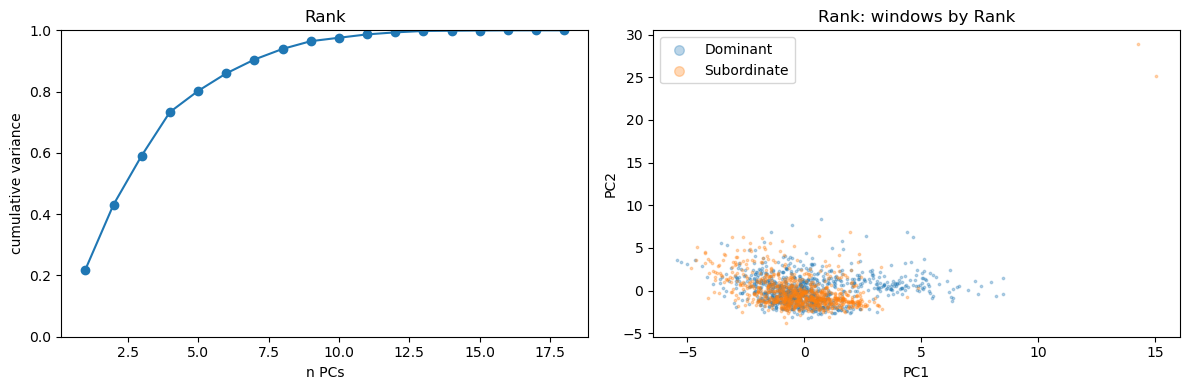

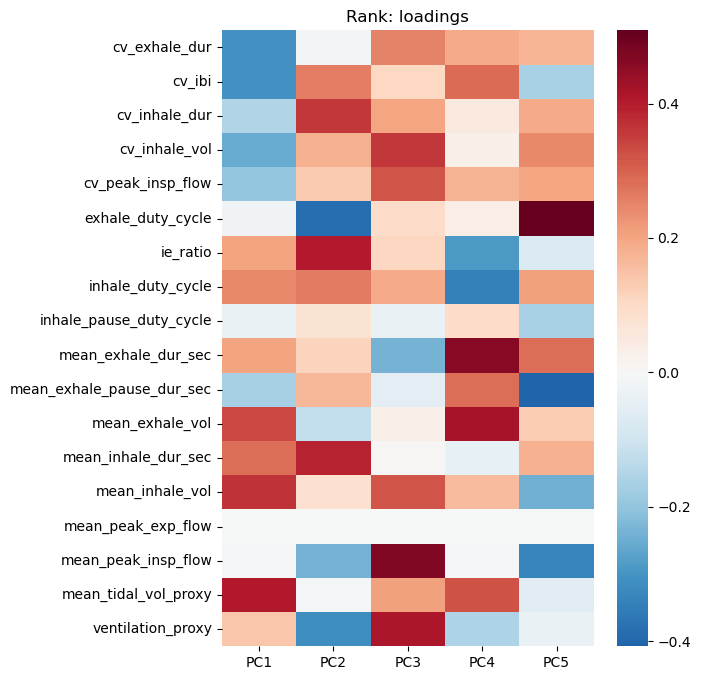

In [8]:
lengths(rank, "Rank")
gaussian(rank, "Rank")
RANK_KEEP, RANK_DROP = redundancy(rank, "Rank")
RANK_PCA, RANK_SCORES, RANK_COLS = pca_check(rank, "Rank", cols=RANK_KEEP, hue="Rank")
RANK_PCS = save_pcs(RANK_PCA, RANK_SCORES, RANK_COLS, rank, "rank")

# Features redundant in BOTH datasets are the safe ones to drop everywhere.
print("\ndrop in both:", sorted(set(VAL_DROP) & set(RANK_DROP)))
print("drop in only one:", sorted(set(VAL_DROP) ^ set(RANK_DROP)))